# A/B-тест «вход в звонок по ссылке без регистрации» на синтетических данных

**Платформа тематических сообществ.**

Реальных пользователей у платформы пока нет, поэтому схему событий, метрики и дизайн эксперимента проверяем на **синтетических данных**:

1. `generate.py` — «придумывает» 24 000 человек, делит их на группы A и B и проигрывает путь каждого по воронке. Пишет события в бронзовый слой по схеме событий платформы и нарочно подмешивает «грязь».
2. `pipeline.py` — чистит данные: Bronze → Silver → Gold, карантин с причинами, склейка гостя с аккаунтом.
3. `analysis.py` — считает метрики и A/B-тест, строит графики.

Эффект в группе B **заложен заранее** (у гостей +12 п.п. к конверсии в звонок). Так проверяем сам метод: должен ли тест его найти и не находит ли он эффект там, где его нет (A/A-тест).

> Все вероятности в генераторе — допущения модели, а не реальные данные. Они собраны в `Config` в начале `generate.py`: их можно поменять и перезапустить ноутбук.

In [1]:
import pandas as pd
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.width', 160)
from IPython.display import Image, display

import generate, pipeline, analysis
cfg = generate.Config()
print('Участников эксперимента:', cfg.n_people, '| набор:', cfg.enroll_days, 'дн. | наблюдение:', cfg.observe_days, 'дн.')
print('Заложенные конверсии в звонок (группа, сегмент):')
for k, v in cfg.p_call_join.items():
    print(f'  {k}: {v:.0%}')

Участников эксперимента: 24000 | набор: 21 дн. | наблюдение: 21 дн.
Заложенные конверсии в звонок (группа, сегмент):
  ('A', 'guest'): 30%
  ('B', 'guest'): 42%
  ('A', 'user'): 66%
  ('B', 'user'): 67%
  ('A', 'member'): 80%
  ('B', 'member'): 80%


## 1. Генерация бронзового слоя
События: `invite_link_opened`, `call_joined`, `registration_completed`, `community_joined`, `community_interaction`, `error_occurred`, `community_left`. Группа назначается по хешу устройства — один человек всегда в одной группе.

In [2]:
tables = generate.generate(cfg)
bronze = tables['bronze_events']
display(bronze.head(8))
display(bronze.event_type.value_counts().rename('событий').to_frame())

Генерация синтетических данных…


  событий без грязи: 319125
  грязь: +4787 дублей, всего строк 319125 -> 323912


  сохранено в /home/user/testdiscord/analytics/synthetic/ab_experiment/data/: bronze_events.csv (323912), communities.csv (40), invites.csv (196), assignments.csv (24000)


,event_id,event_type,timestamp,user_id,anonymous_id,device_id,platform_id,invite_id,community_id,call_id,message_id,join_status,registration_source,join_source,action_type,duration_sec,error_type,leave_reason
0,evt_00080665,community_interaction,2026-09-22 11:44:00+0300,user_old_01549,NaN,NaN,android,NaN,comm_031,NaN,msg_36d805d3f5b2,NaN,NaN,NaN,message,<NA>,NaN,NaN
1,evt_00088033,community_interaction,2026-09-15 12:11:00+0300,user_old_01696,NaN,NaN,android,NaN,comm_012,NaN,msg_d49a9a3cffd7,NaN,NaN,NaN,message,<NA>,NaN,NaN
2,evt_00151492,community_interaction,2026-10-18 23:27:00+0300,user_old_02897,NaN,NaN,android,NaN,comm_003,NaN,msg_acfa8dbe5f38,NaN,NaN,NaN,message,<NA>,NaN,NaN
3,evt_00225762,community_interaction,2026-10-07 10:58:00+0300,user_010490,NaN,dev_010490,web,NaN,comm_004,NaN,msg_3cc4f66656e7,NaN,NaN,NaN,message,<NA>,NaN,NaN
4,evt_00294304,call_joined,2026-09-07 12:44:00+0300,user_020391,anon_020391,dev_020391,web,inv_d9e3c325caeb,comm_030,call_435c3f5d96dc,NaN,success,NaN,NaN,NaN,<NA>,NaN,NaN
5,evt_00157657,invite_link_opened,2026-09-16 19:42:00+0300,user_000156,anon_000156,dev_000156,ios,inv_2cb54dae31df,comm_029,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN
6,evt_00016078,community_interaction,2026-10-18 19:37:00+0300,user_old_00308,NaN,NaN,web,NaN,comm_001,call_0fbf9738cc08,NaN,NaN,NaN,NaN,call,2702,NaN,NaN
7,evt_00040642,community_interaction,2026-10-02 18:59:00+0300,user_old_00764,NaN,NaN,web,NaN,comm_003,call_fc835127b025,NaN,NaN,NaN,NaN,call,1145,NaN,NaN


,событий
event_type,
community_interaction,270801
invite_link_opened,27352
call_joined,14158
community_joined,5579
registration_completed,4962
error_occurred,603
community_left,457


## 2. Silver: проверки качества
Полнота (event_id, время, идентификатор человека, обязательные поля), уникальность event_id, допустимые значения (`action_type`, `join_status`, неотрицательная длительность), существование сообщества и приглашения в справочниках. Всё, что не прошло, — в карантин с причиной. Время приводится к UTC, `anonymous_id` склеивается с `user_id` после регистрации.

In [3]:
r = pipeline.run()
silver, quarantine, people = r['silver'], r['quarantine'], r['people']
print(f'Bronze: {len(bronze):,}  →  Silver: {len(silver):,}  |  карантин: {len(quarantine):,} ({len(quarantine)/len(bronze):.1%})')
display(quarantine.reason.value_counts().rename('строк в карантине').to_frame())

Bronze: 323912  ->  Silver: 316892,  карантин: 7020
reason
duplicate_event_id    4787
missing_person_id      963
unknown_community      664
bad_action_type        542
bad_join_status         35
negative_duration       29


Bronze: 323,912  →  Silver: 316,892  |  карантин: 7,020 (2.2%)


,строк в карантине
reason,
duplicate_event_id,4787
missing_person_id,963
unknown_community,664
bad_action_type,542
bad_join_status,35
negative_duration,29


## 3. Gold: воронка и WECU
Воронка нового пользователя по группам и сегментам. Сегменты фиксируются в момент открытия ссылки: гость без аккаунта / с аккаунтом / уже участник сообщества.

In [4]:
display(r['funnel'])
display(r['funnel_seg'])
display(r['weekly'])

,opened_invite,call_joined,registered_new,community_joined,activated,retained_d7,cr_call_join
group,,,,,,,
A,12070,5116,2608,2762,"1,442.0000","1,006.0000",0.4239
B,11808,6154,2242,2677,"1,295.0000",887.0000,0.5212


opened_invite  call_joined  registered_new  community_joined  activated  retained_d7  cr_call_join
segment group                                                                                                    
guest   A               7957         2266            2608              1616   841.0000     574.0000        0.2848
        B               7681         3217            2242              1538   720.0000     529.0000        0.4188
member  A               1636         1286               0                 0     0.0000       0.0000        0.7861
        B               1638         1273               0                 0     0.0000       0.0000        0.7772
user    A               2477         1564               0              1146   601.0000     432.0000        0.6314
        B               2489         1664               0              1139   575.0000     358.0000        0.6685

,active_users,wecu,messages,call_minutes
week,,,,
2026-09-07/2026-09-13,4202,2584,29567,"135,713.0000"
2026-09-14/2026-09-20,5816,3643,41539,"188,404.0000"
2026-09-21/2026-09-27,7135,4454,51485,"237,002.0000"
2026-09-28/2026-10-04,6317,4121,48565,"218,787.0000"
2026-10-05/2026-10-11,4692,3063,36901,"164,381.0000"
2026-10-12/2026-10-18,3343,2215,25939,"118,941.0000"


## 4. Планирование: размер выборки и длительность
$n \approx 2 (z_{1-\alpha/2} + z_{1-\beta})^2 \cdot \bar p(1-\bar p) / \Delta^2$, α = 0,05, мощность 80%. Базовую конверсию p₁ берём из первой недели группы A — в реальности её берут из исторических данных.

In [5]:
res = analysis.run(people, r['weekly'])
pl = res['planning']
print(f"p₁ = {pl['p1']:.3f},  MDE = {pl['mde']:.0%}  →  n = {pl['n_per_group']:,} на группу, всего {pl['total']:,}")
print(f"Открытий в день ≈ {pl['opens_per_day']:.0f}  →  длительность: {pl['days']} дней (не меньше 14)")
print('Как выборка зависит от MDE:', {f'{k:.0%}': f'{v:,}' for k, v in pl['n_for_mde'].items()})

p₁ = 0.428,  MDE = 3%  →  n = 4,304 на группу, всего 8,608
Открытий в день ≈ 1137  →  длительность: 14 дней (не меньше 14)
Как выборка зависит от MDE: {'1%': '38,542', '2%': '9,661', '3%': '4,304', '5%': '1,556'}


## 5. Баланс групп (SRM)
Фактическое деление сравниваем с 50/50 критерием хи-квадрат. При p < 0,001 результаты не интерпретируем.

In [6]:
s = res['srm']
print(f"A: {s['n_A']:,}  B: {s['n_B']:,}  доля B: {s['share_B']:.3f}  χ² = {s['chi2']:.2f}  p = {s['p_value']:.3f}  →  {'баланс в норме' if s['ok'] else 'ПЕРЕКОС, стоп'}")

A: 12,070  B: 11,808  доля B: 0.495  χ² = 2.87  p = 0.090  →  баланс в норме


## 6. Главная метрика: Conversion to Call Join
Уникальные с успешным `call_joined` / уникальные с `invite_link_opened`. z-тест двух долей, двусторонний, α = 0,05.

In [7]:
m = res['main']
print(f"A: {m['A']:.2%}   B: {m['B']:.2%}")
print(f"Разница B − A: {m['diff']*100:+.1f} п.п., 95% ДИ [{m['ci_low']*100:+.1f}; {m['ci_high']*100:+.1f}] п.п., относительный прирост {m['lift']:+.1%}")
print(f"z = {m['z']:.2f}, p-value = {m['p_value']:.2e}  →  {'значимо' if m['significant'] else 'не значимо'}")

A: 42.19%   B: 51.80%
Разница B − A: +9.6 п.п., 95% ДИ [+8.3; +10.9] п.п., относительный прирост +22.8%
z = 14.87, p-value = 0.00e+00  →  значимо


## 7. Защитные метрики
Границы фиксируем до запуска: Activation Rate и Retention D7 в B — не ниже A больше чем на 5 п.п., ранний выход — не выше больше чем на 5 п.п., доля ошибок — не выше больше чем на 30% относительно.

In [8]:
display(res['guardrails'])

,Метрика,A,B,Разница B−A,ДИ 95%,p-value,Граница,Статус
0,Activation Rate,0.5221,0.4838,-0.0383,[-0.065; -0.012],0.0047,−5 п.п.,в границах
1,Доля раннего выхода,0.0702,0.0960,0.0258,[+0.011; +0.040],0.0006,+5 п.п.,в границах
2,Community Retention D7,0.3642,0.3313,-0.0329,[-0.058; -0.008],0.0109,−5 п.п.,в границах
3,Доля технических ошибок,0.0366,0.0470,0.0104,[+0.004; +0.017],0.0031,+30% относительно,в границах


## 8. Сегменты (поправка Бонферрони) и диагностика воронки

,Сегмент,n A,n B,A,B,Разница,ДИ (с поправкой),p-value,Значимо при α=0.0167
0,Гость (без аккаунта),7957,7681,0.2840,0.4160,0.1319,[+0.114; +0.150],0.0000,да
1,"С аккаунтом, не в сообществе",2477,2489,0.6274,0.6637,0.0363,[+0.004; +0.069],0.0074,да
2,Уже участник сообщества,1636,1638,0.7812,0.7747,-0.0064,[-0.041; +0.028],0.6571,нет


Группа,A,B
Открыли → звонок,0.4219,0.5180
Гость: звонок → регистрация,1.0000,0.6901
Гость: открыл → регистрация,0.3270,0.2894
Регистрация → вступление,0.6195,0.6851
Вступление → активация,0.5231,0.4804


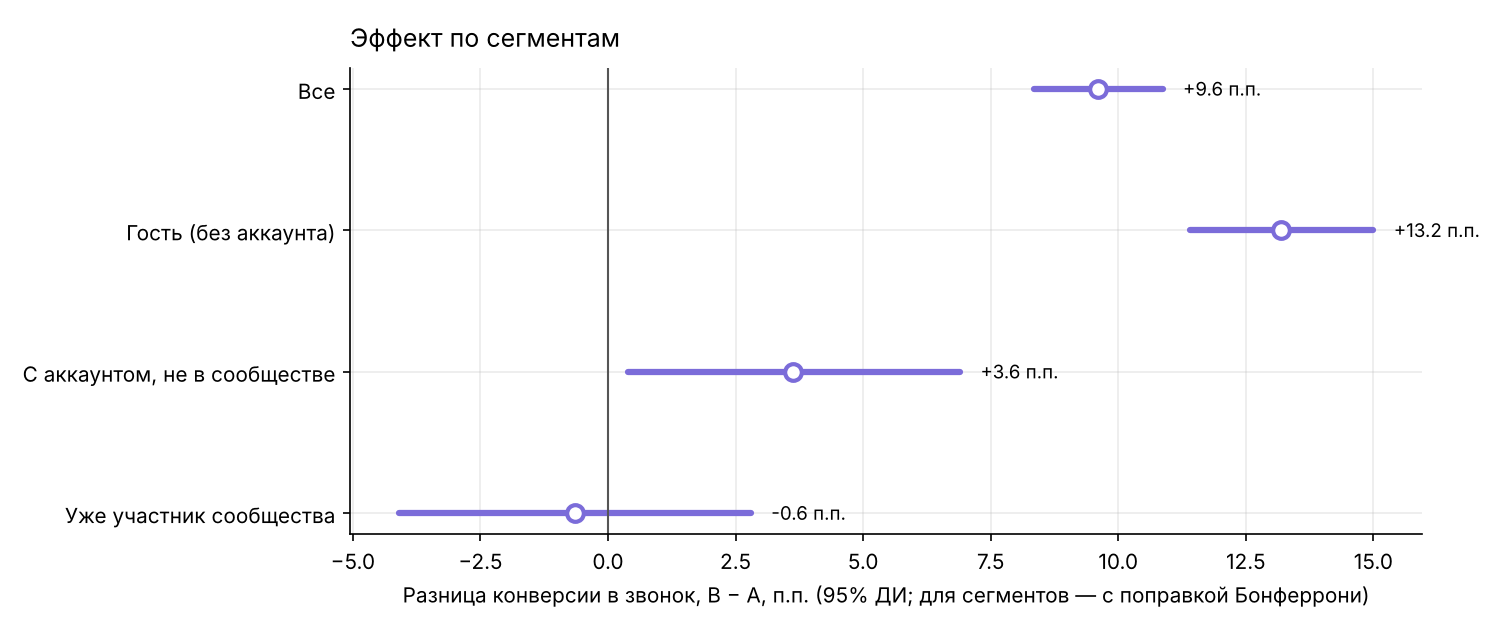

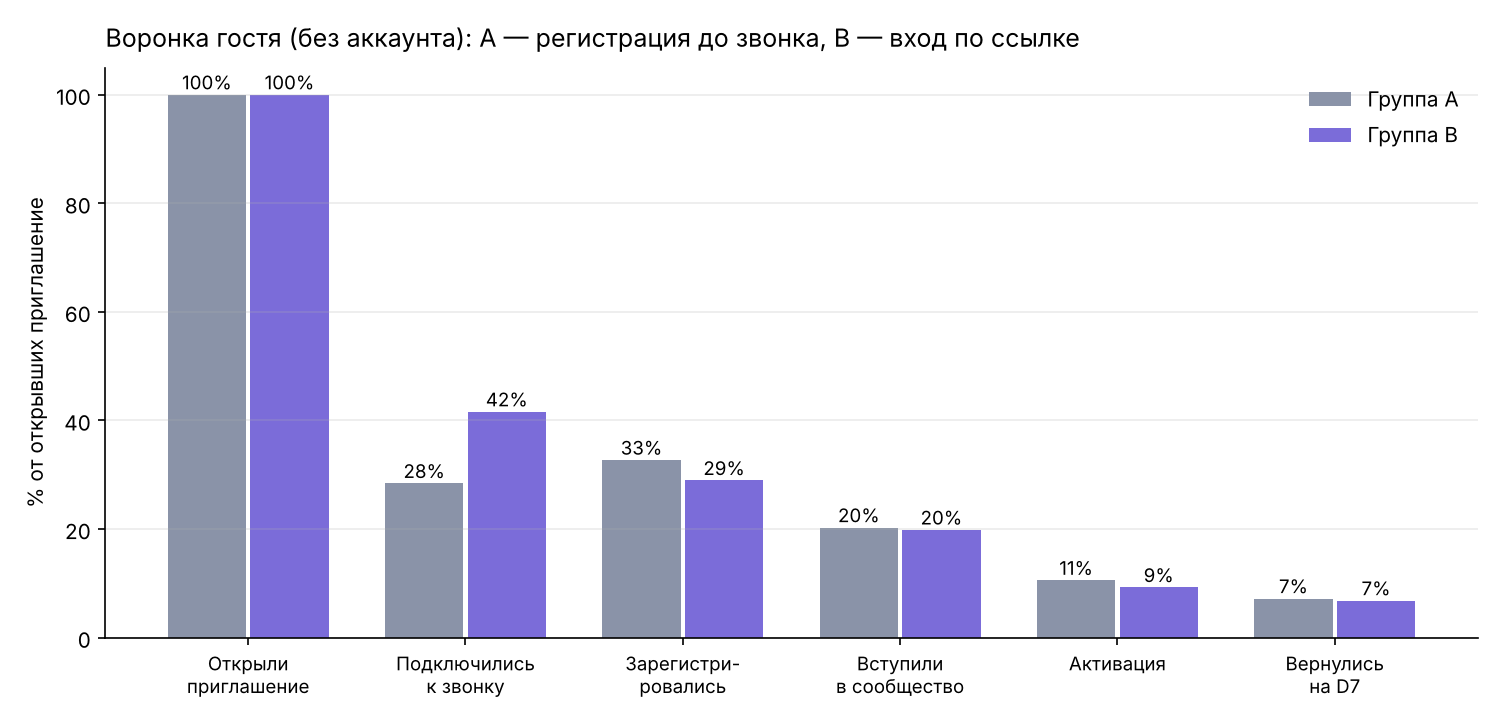

In [9]:
display(res['segments'])
display(res['diagnostics'])
display(Image(res['charts']['segments']))
display(Image(res['charts']['funnel']))

## 9. Последовательный мониторинг
Проверки после 7, 14 и 21 дня. Границы О'Брайена–Флеминга строже обычных 1,96 на ранних проверках, поэтому ежедневные взгляды на результат не повышают риск ложного вывода. По плану эксперимента досрочно останавливаемся только при вреде; решение по главной метрике — не раньше 14 дней.

,Проверка,Участников,A,B,z,Граница |z|,Пересекли
0,день 7,6782,0.4345,0.5402,8.7078,3.4710,да
1,день 14,14708,0.4264,0.5240,11.8475,2.4544,да
2,день 21,22768,0.4223,0.5200,14.7587,2.0040,да


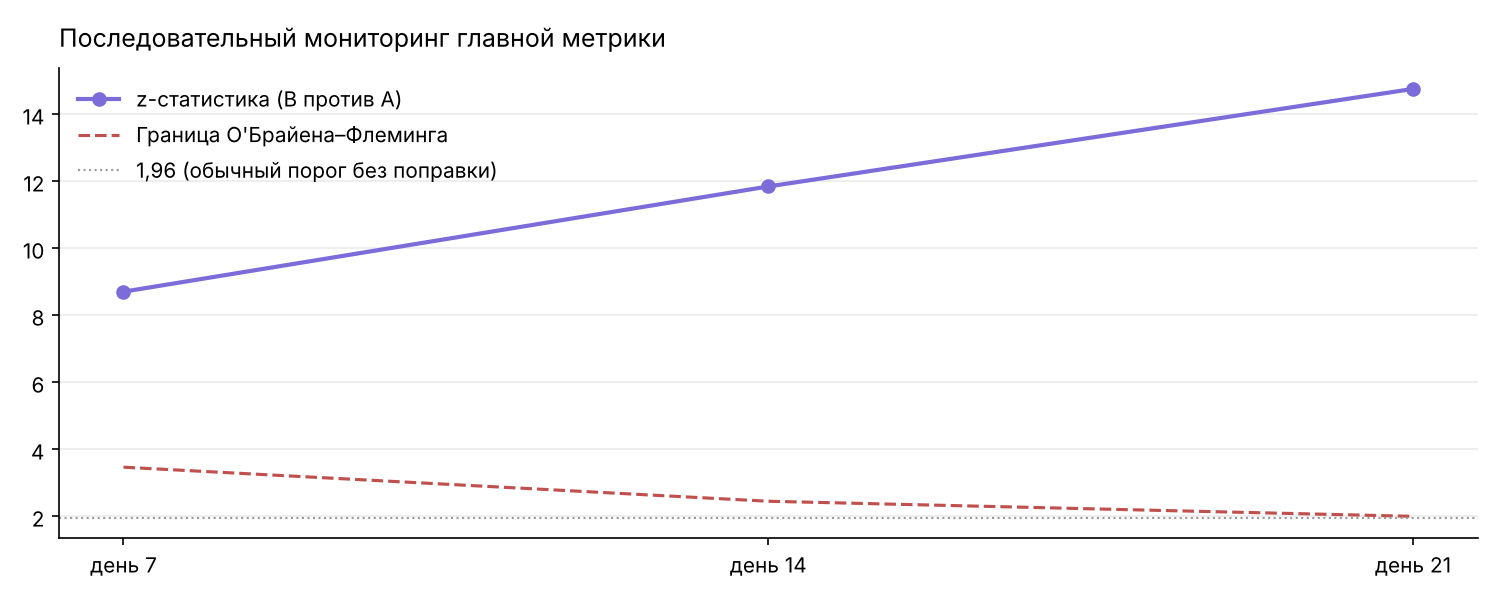

In [10]:
display(res['monitoring'])
display(Image(res['charts']['monitoring']))

## 10. A/A-тест: проверка самого метода
Берём только группу A, 1000 раз случайно делим её пополам и сравниваем. Эффекта нет, поэтому значимых результатов должно быть около 5%, а p-value — распределены равномерно.

Ложных срабатываний: 3.6% (норма ≈ 5%);  тест равномерности p-value (KS): p = 0.062


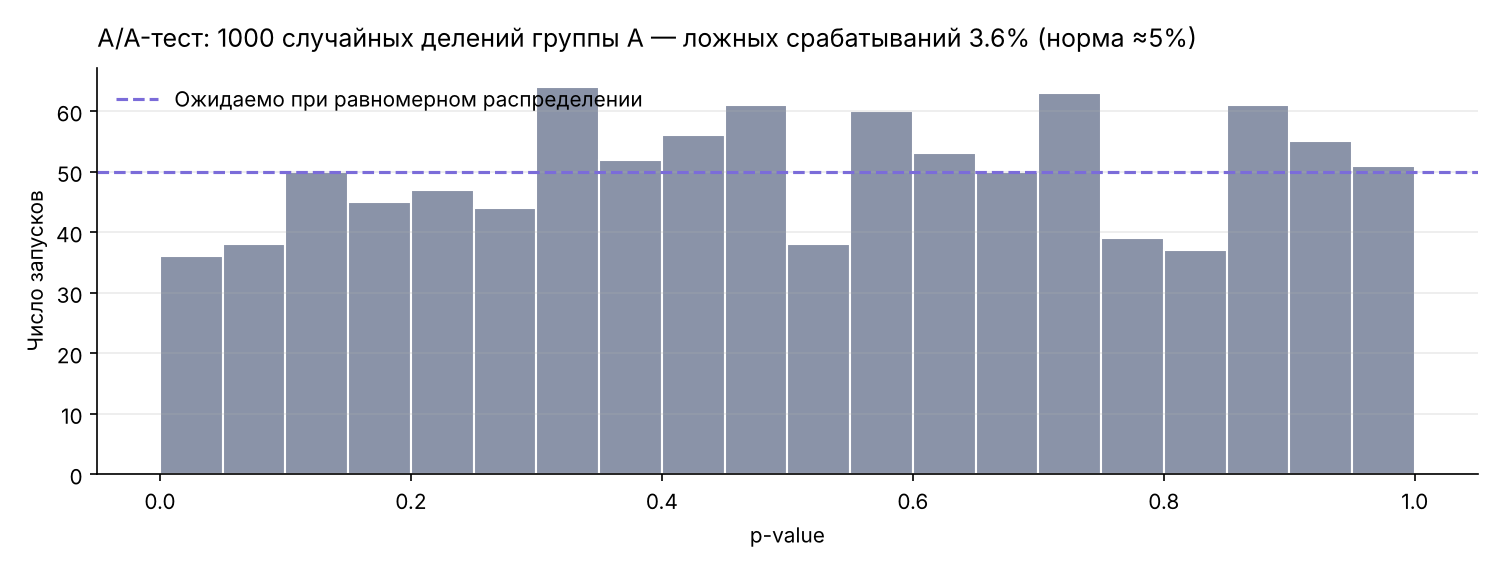

In [11]:
aa = res['aa']
print(f"Ложных срабатываний: {aa['false_positive_rate']:.1%} (норма ≈ 5%);  тест равномерности p-value (KS): p = {aa['ks_p_value']:.3f}")
display(Image(res['charts']['aa']))

## 11. WECU по неделям

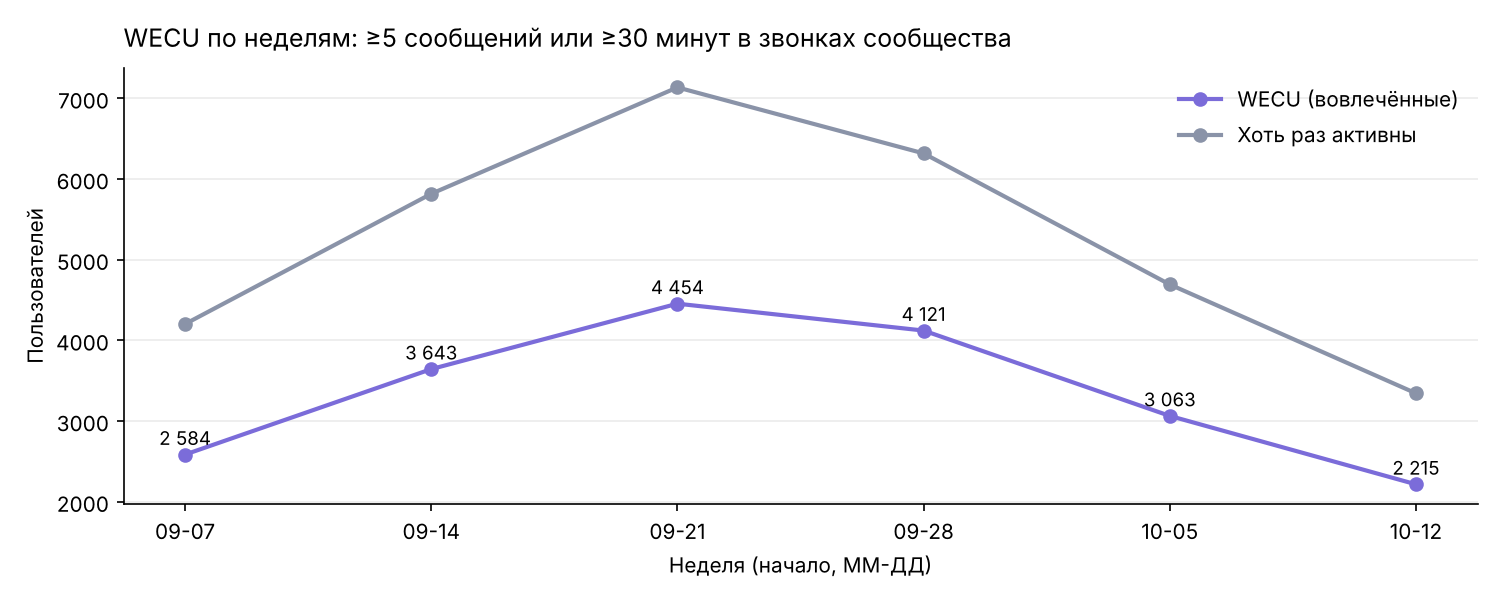

In [12]:
display(Image(res['charts']['wecu']))

### Выводы — посчитаны из результатов выше

In [13]:
true = {s: cfg.p_call_join[('B', s)] - cfg.p_call_join[('A', s)] for s in ['guest', 'user', 'member']}
seg = res['segments']
print('Нашёл ли тест заложенный эффект (конверсия в звонок, B − A):')
for (key, label), row in zip(analysis.SEGMENT_LABELS.items(), seg.itertuples()):
    lo, hi = (float(x) for x in row[7].strip('[]').split(';'))
    covered = lo <= true[key] <= hi
    print(f'  {label}: заложено {true[key]*100:+.0f} п.п., оценка {row.Разница*100:+.1f} п.п., ДИ [{lo*100:+.1f}; {hi*100:+.1f}]'
          f' — {"накрывает" if covered else "НЕ накрывает"} истинное значение')
print(f"A/A-тест: ложных срабатываний {res['aa']['false_positive_rate']:.1%} при норме около 5%.")
g = res['guardrails']
worse = g[(g['Разница B−A'] < 0) & g['Метрика'].isin(['Activation Rate', 'Community Retention D7'])]
print(f"Защитные метрики: {', '.join(g['Статус'].unique())}; в B ниже: {', '.join(worse['Метрика']) or 'нет'}.")
d = res['diagnostics']
print(f"Регистрации гостей (открыл → регистрация): A {d.loc['Гость: открыл → регистрация', 'A']:.1%}, B {d.loc['Гость: открыл → регистрация', 'B']:.1%}"
      ' — это следствие допущения в генераторе (сколько гостей регистрируются после звонка), на реальных данных — главный вопрос вторичной гипотезы.')
print()
print('Решение:', res['decision'])

Нашёл ли тест заложенный эффект (конверсия в звонок, B − A):
  Гость (без аккаунта): заложено +12 п.п., оценка +13.2 п.п., ДИ [+11.4; +15.0] — накрывает истинное значение
  С аккаунтом, не в сообществе: заложено +1 п.п., оценка +3.6 п.п., ДИ [+0.4; +6.9] — накрывает истинное значение
  Уже участник сообщества: заложено +0 п.п., оценка -0.6 п.п., ДИ [-4.1; +2.8] — накрывает истинное значение
A/A-тест: ложных срабатываний 3.6% при норме около 5%.
Защитные метрики: в границах; в B ниже: Activation Rate, Community Retention D7.
Регистрации гостей (открыл → регистрация): A 32.7%, B 28.9% — это следствие допущения в генераторе (сколько гостей регистрируются после звонка), на реальных данных — главный вопрос вторичной гипотезы.

Решение: Внедряем: конверсия в B значимо выше, защитные метрики в границах. Небольшое снижение активации и удержания в B стоит наблюдать после запуска.


Тот же `pipeline.py` и `analysis.py` можно запустить на реальных событиях платформы: поля и названия событий совпадают со схемой событий платформы. Параметры модели меняются в `Config` в начале `generate.py`.